# Kestrel Returns Intelligence Platform
## An AI-Powered Operational Decision Support System for Pre-Dispatch Return Prevention (Variant A)

**Author:** Senior Machine Learning Engineer  
**System Architecture:**
1. **Interactive Ingestion & Anomaly Audit:** October 2025 gateway paise bug correction & partner feed deduplication
2. **Leakage-Free Preprocessing:** Strict post-dispatch event purging (`pickup_scheduled_at`, `last_service_event_type`)
3. **Feature Ablation Study (5 Levels):** Base Order $\rightarrow$ Customer Profile $\rightarrow$ Product Mechanics $\rightarrow$ Delivery NLP $\rightarrow$ Non-Linear Cross Features
4. **Multi-Model Benchmark (5 Families):** Logistic Regression, Random Forest, LightGBM, XGBoost, CatBoost with class imbalance weighting
5. **Expanded Hyperparameter Tuning:** Automated grid search over depth, regularization, learning rate, and scale_pos_weight
6. **Multi-Curve Production Diagnostics:** AUROC, PR-AUC, Calibration Reliability Curve, Confusion Matrices, and Expected Profit Curve in INR (₹)
7. **Global Explainability:** Top 20 SHAP / CatBoost Feature Importances
8. **Error Analysis & Distribution Shift Audit:** False Positive vs. False Negative profiling and Train-vs-Test Kolmogorov-Smirnov drift analysis
9. **Batch Scoring & Export:** Scoring `test_unlabelled.csv` (2,096 rows) to `predictions.csv`
10. **Interactive Order Evaluation Widget:** Real-time single order risk scoring, P&L net savings, and operational action routing



## Step 1: Install Required Libraries


In [1]:
!pip install -q catboost lightgbm xgboost scikit-learn pandas numpy matplotlib seaborn scipy joblib


## Step 2: Upload & Load Datasets
Upload or locate the 4 core CSV datasets:
* `train.csv` (11,155 historical transactions)
* `test_unlabelled.csv` (2,096 orders to score)
* `customers.csv` (5,000 customer profiles)
* `products.csv` (21 appliance SKUs)



In [2]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
import warnings
warnings.filterwarnings('ignore')

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def find_file(pattern):
    matches = glob.glob(pattern) or glob.glob('Datasets/' + pattern) or glob.glob('*/' + pattern)
    return matches[0] if matches else None

train_path = find_file('*train.csv')
test_path = find_file('*test_unlabelled.csv')
cust_path = find_file('*customers.csv')
prod_path = find_file('*products.csv')

if IN_COLAB and (not train_path or not test_path):
    print("Please upload train.csv, test_unlabelled.csv, customers.csv, and products.csv:")
    from google.colab import files
    uploaded = files.upload()
    train_path = find_file('*train.csv')
    test_path = find_file('*test_unlabelled.csv')
    cust_path = find_file('*customers.csv')
    prod_path = find_file('*products.csv')

print("Loaded file paths:")
print(f"  Train:     {train_path}")
print(f"  Test:      {test_path}")
print(f"  Customers: {cust_path}")
print(f"  Products:  {prod_path}")

train_raw = pd.read_csv(train_path)
test_raw = pd.read_csv(test_path)
customers = pd.read_csv(cust_path)
products = pd.read_csv(prod_path)

print(f"\nRecord Counts: Train={train_raw.shape}, Test={test_raw.shape}, Customers={customers.shape}, Products={products.shape}")



Loaded file paths:
  Train:     9b5e6f77-f4dc-45d4-a0a8-262137de37ce-train.csv
  Test:      45c3e718-f34f-47cc-9501-5953434d0fe4-test_unlabelled.csv
  Customers: 449d665c-c66b-490d-83c6-cca62a0538e2-customers.csv
  Products:  c9e8afbe-9307-46ff-a798-89bf9b8e3a9c-products.csv

Record Counts: Train=(11155, 19), Test=(2096, 18), Customers=(9000, 5), Products=(21, 6)


## Step 3: Class Imbalance & Data Quality Audit
1. **Base Rate:** Returns account for **11.4%** of orders (~8:1 imbalance ratio).
2. **October 2025 Gateway Paise Bug:** Gateway software release logged amounts in paise ($100\times$).
3. **Partner Feed Duplicates:** 651 duplicate order pairs in `train.csv`.
4. **Target Leakage:** `pickup_scheduled_at` and `last_service_event_type` exist in `train.csv` but are post-dispatch events!



In [3]:
returns_count = train_raw['returned'].value_counts()
returns_pct = train_raw['returned'].value_counts(normalize=True) * 100
spw = returns_count[0] / returns_count[1]

print("=== CLASS IMBALANCE AUDIT ===")
print(f"Class 0 (Kept):     {returns_count[0]:,} orders ({returns_pct[0]:.2f}%)")
print(f"Class 1 (Returned): {returns_count[1]:,} orders ({returns_pct[1]:.2f}%)")
print(f"Inverse Ratio (scale_pos_weight): {spw:.2f}")

# Paise Bug Audit
train_raw['order_placed_at'] = pd.to_datetime(train_raw['order_placed_at'])
train_with_prod = train_raw.merge(products[['sku', 'list_price_inr']], on='sku', how='left')
train_with_prod['expected_val'] = train_with_prod['list_price_inr'] * train_with_prod['qty'] * (1 - train_with_prod['discount_pct'] / 100.0)
train_with_prod['price_ratio'] = train_with_prod['order_value_inr'] / train_with_prod['expected_val']

oct_orders = train_with_prod[(train_with_prod['order_placed_at'].dt.year == 2025) & (train_with_prod['order_placed_at'].dt.month == 10)]
non_oct = train_with_prod[~((train_with_prod['order_placed_at'].dt.year == 2025) & (train_with_prod['order_placed_at'].dt.month == 10))]
print(f"\nOctober 2025 Orders Mean Price Ratio: {oct_orders['price_ratio'].mean():.1f}x (Paise Bug Detected!)")
print(f"All Other Months Mean Price Ratio:     {non_oct['price_ratio'].mean():.1f}x (Clean)")



=== CLASS IMBALANCE AUDIT ===
Class 0 (Kept):     9,888 orders (88.64%)
Class 1 (Returned): 1,267 orders (11.36%)
Inverse Ratio (scale_pos_weight): 7.80

October 2025 Orders Mean Price Ratio: 100.0x (Paise Bug Detected!)
All Other Months Mean Price Ratio:     1.0x (Clean)


## Step 4: Leakage-Free Preprocessing Pipeline
We construct `KestrelPreprocessor` ensuring:
* Strict purging of `pickup_scheduled_at`, `last_service_event_type`, and `returned`
* Paise bug correction (`order_value_inr / 100`)
* Collision-free merging of customer and product attributes
* NLP extraction on `delivery_note` (gate code, no lift, fragile, call before, security)
* 43 engineered features across 5 operational levels



In [4]:
class KestrelPreprocessor:
    def __init__(self, customers_df=None, products_df=None):
        self.customers_df = customers_df.copy() if customers_df is not None else None
        self.products_df = products_df.copy() if products_df is not None else None
        self.family_target_enc = {}
        self.state_target_enc = {}
        self.global_mean_return = 0.1142
        self.feature_columns = []

    @staticmethod
    def fix_gateway_anomaly(df):
        df = df.copy()
        if 'order_placed_at' in df.columns and 'order_value_inr' in df.columns:
            dates = pd.to_datetime(df['order_placed_at'], errors='coerce')
            mask_oct = (dates.dt.year == 2025) & (dates.dt.month == 10)
            df.loc[mask_oct, 'order_value_inr'] = df.loc[mask_oct, 'order_value_inr'] / 100.0
        return df

    def fit(self, train_df, y):
        train_df = self.fix_gateway_anomaly(train_df)
        if 'family' not in train_df.columns and self.products_df is not None:
            train_df = train_df.merge(self.products_df, on='sku', how='left')
        if 'state' not in train_df.columns and self.customers_df is not None:
            train_df = train_df.merge(self.customers_df, on='customer_id', how='left')

        self.global_mean_return = float(y.mean())
        m = 10.0
        for fam, row in y.groupby(train_df['family']).agg(['count', 'mean']).iterrows():
            self.family_target_enc[fam] = (row['count'] * row['mean'] + m * self.global_mean_return) / (row['count'] + m)
        for st, row in y.groupby(train_df['state']).agg(['count', 'mean']).iterrows():
            self.state_target_enc[st] = (row['count'] * row['mean'] + m * self.global_mean_return) / (row['count'] + m)

        transformed = self.transform(train_df)
        self.feature_columns = list(transformed.columns)
        return self

    def transform(self, df):
        df = df.copy()
        for col in ['pickup_scheduled_at', 'last_service_event_type', 'returned']:
            if col in df.columns:
                df = df.drop(columns=[col])

        df = self.fix_gateway_anomaly(df)

        if self.products_df is not None:
            prod_cols = [c for c in self.products_df.columns if c not in df.columns or c == 'sku']
            df = df.merge(self.products_df[prod_cols], on='sku', how='left')

        if self.customers_df is not None:
            cust_cols = [c for c in self.customers_df.columns if c not in df.columns or c == 'customer_id']
            df = df.merge(self.customers_df[cust_cols], on='customer_id', how='left')

        for c in ['shield_member', 'city', 'state', 'family', 'model_name', 'list_price_inr', 'warranty_months', 'signup_date', 'launch_date']:
            if c not in df.columns:
                if f'{c}_x' in df.columns:
                    df[c] = df[f'{c}_x']
                elif f'{c}_y' in df.columns:
                    df[c] = df[f'{c}_y']
                elif c == 'shield_member':
                    df[c] = 'N'

        if 'order_placed_at' not in df.columns:
            df['order_placed_at'] = pd.Timestamp.now().strftime('%Y-%m-%d %H:%M')
        if 'order_value_inr' not in df.columns:
            df['order_value_inr'] = 0.0
        if 'payment_mode' not in df.columns:
            df['payment_mode'] = 'prepaid_upi'
        if 'sku' not in df.columns:
            df['sku'] = 'KH-AF-01'
        if 'sales_channel' not in df.columns:
            df['sales_channel'] = 'app'
        if 'shield_member' not in df.columns:
            df['shield_member'] = 'N'
        if 'delivery_pincode' not in df.columns:
            df['delivery_pincode'] = '440365'

        order_dates = pd.to_datetime(df['order_placed_at'], errors='coerce')
        signup_dates = pd.to_datetime(df.get('signup_date', order_dates), errors='coerce')
        launch_dates = pd.to_datetime(df.get('launch_date', order_dates), errors='coerce')

        clean_val = pd.to_numeric(df['order_value_inr'], errors='coerce').fillna(0)
        list_price = pd.to_numeric(df.get('list_price_inr', 0), errors='coerce').fillna(0)
        qty = pd.to_numeric(df.get('qty', 1), errors='coerce').fillna(1)
        discount_pct = pd.to_numeric(df.get('discount_pct', 0), errors='coerce').fillna(0)
        promised_days = pd.to_numeric(df.get('promised_delivery_days', 5), errors='coerce').fillna(5)

        prior_orders = pd.to_numeric(df.get('customer_prior_orders', 0), errors='coerce').fillna(0)
        prior_returns = pd.to_numeric(df.get('customer_prior_returns', 0), errors='coerce').fillna(0)
        prior_return_ratio = prior_returns / np.maximum(prior_orders, 1.0)
        is_chronic_returner = (prior_returns >= 2).astype(int)

        tenure_days = (order_dates - signup_dates).dt.days.fillna(0).clip(lower=0)
        order_velocity = prior_orders / ((tenure_days / 30.0) + 1.0)
        shield_member = df['shield_member'].astype(str).str.upper().eq('Y').astype(int)

        is_cod = df['payment_mode'].astype(str).str.lower().eq('cod').astype(int)
        absolute_discount = np.maximum((list_price * qty) - clean_val, 0.0)
        price_ratio = clean_val / np.maximum(list_price * qty, 1.0)

        model_names = df.get('model_name', '').astype(str)
        model_tier = pd.Series(1, index=df.index)
        model_tier[model_names.str.contains('Pro', case=False)] = 2
        model_tier[model_names.str.contains('Max', case=False)] = 3
        warranty = pd.to_numeric(df.get('warranty_months', 12), errors='coerce').fillna(12)
        price_per_warranty = list_price / np.maximum(warranty, 1.0)

        text = df.get('delivery_note', pd.Series(index=df.index)).fillna('').astype(str).str.lower()
        note_is_missing = df.get('delivery_note', pd.Series(index=df.index)).isna().astype(int)
        note_call_before = text.str.contains(r'call before|whatsapp|do not call').astype(int)
        note_gate_code = text.str.contains(r'gate code').astype(int)
        note_no_lift = text.str.contains(r'no lift|third floor|stairs').astype(int)
        note_security = text.str.contains(r'security|guard').astype(int)
        note_fragile = text.str.contains(r'fragile').astype(int)
        note_neighbour = text.str.contains(r'neighbour|neighbor').astype(int)

        hour = order_dates.dt.hour.fillna(12).astype(int)
        is_late_night = hour.isin([23, 0, 1, 2, 3, 4]).astype(int)
        is_weekend = order_dates.dt.dayofweek.fillna(0).isin([5, 6]).astype(int)

        pincodes = df.get('delivery_pincode', '440365').astype(str).str.zfill(6)
        pincode_prefix = pincodes.str[:2]
        state_str = df.get('state', 'MH').astype(str)

        is_robot_vac = df.get('family', '').astype(str).eq('Robot Vacuum').astype(int)
        is_air_fryer = df.get('family', '').astype(str).eq('Air Fryer').astype(int)

        feat_df = pd.DataFrame(index=df.index)
        # Raw categoricals
        feat_df['sku'] = df['sku'].astype(str)
        feat_df['payment_mode'] = df['payment_mode'].astype(str)
        feat_df['sales_channel'] = df['sales_channel'].astype(str)
        feat_df['city'] = df.get('city', 'Unknown').astype(str)
        feat_df['state'] = state_str
        feat_df['family'] = df.get('family', 'Unknown').astype(str)
        feat_df['pincode_prefix'] = pincode_prefix

        # Numeric / Engineered
        feat_df['order_value'] = clean_val
        feat_df['qty'] = qty
        feat_df['discount_pct'] = discount_pct
        feat_df['promised_delivery_days'] = promised_days
        feat_df['prior_orders'] = prior_orders
        feat_df['prior_returns'] = prior_returns
        feat_df['prior_return_ratio'] = prior_return_ratio
        feat_df['is_chronic_returner'] = is_chronic_returner
        feat_df['is_first_buyer'] = (prior_orders == 0).astype(int)
        feat_df['tenure_days'] = tenure_days
        feat_df['order_velocity'] = order_velocity
        feat_df['shield_member'] = shield_member

        feat_df['model_tier'] = model_tier
        feat_df['list_price'] = list_price
        feat_df['warranty_months'] = warranty
        feat_df['price_per_warranty'] = price_per_warranty
        feat_df['absolute_discount'] = absolute_discount
        feat_df['price_ratio'] = price_ratio

        feat_df['note_is_missing'] = note_is_missing
        feat_df['note_call_before'] = note_call_before
        feat_df['note_gate_code'] = note_gate_code
        feat_df['note_no_lift'] = note_no_lift
        feat_df['note_security'] = note_security
        feat_df['note_fragile'] = note_fragile
        feat_df['note_neighbour'] = note_neighbour
        feat_df['is_late_night'] = is_late_night
        feat_df['is_weekend'] = is_weekend

        # Non-linear cross features
        feat_df['is_cod'] = is_cod
        feat_df['robot_vac_cod_hazard'] = is_robot_vac * is_cod
        feat_df['air_fryer_cod_hazard'] = is_air_fryer * is_cod
        feat_df['shield_cod_hazard'] = shield_member * is_cod
        feat_df['shield_chronic_hazard'] = shield_member * (prior_returns >= 2).astype(int)
        feat_df['high_val_cod_first_timer'] = (clean_val > 8000).astype(int) * is_cod * (prior_orders == 0).astype(int)
        feat_df['deep_discount_cod'] = (discount_pct >= 20).astype(int) * is_cod
        feat_df['delivery_drag_risk'] = promised_days * is_cod
        feat_df['chronic_prior_returns_squared'] = np.square(prior_returns)

        if self.feature_columns:
            feat_df = feat_df.reindex(columns=self.feature_columns, fill_value=0)
        return feat_df

# Deduplicate train on order_id
train_clean = train_raw.drop_duplicates(subset=['order_id'], keep='first').copy()
train_clean['order_placed_at'] = pd.to_datetime(train_clean['order_placed_at'])

split_date = pd.to_datetime('2026-04-01 00:00:00')
train_split = train_clean[train_clean['order_placed_at'] < split_date].copy()
val_split = train_clean[train_clean['order_placed_at'] >= split_date].copy()

preprocessor = KestrelPreprocessor(customers_df=customers, products_df=products)
preprocessor.fit(train_split, train_split['returned'])

X_train_oot = preprocessor.transform(train_split)
y_train_oot = train_split['returned'].values

X_val_oot = preprocessor.transform(val_split)
y_val_oot = val_split['returned'].values

print(f"OOT Training Set (12 mos): {len(X_train_oot)} orders ({y_train_oot.mean():.2%} return rate)")
print(f"OOT Validation Set (3 mos): {len(X_val_oot)} orders ({y_val_oot.mean():.2%} return rate)")
print(f"Engineered Features: {X_train_oot.shape[1]}")



OOT Training Set (12 mos): 8378 orders (11.40% return rate)
OOT Validation Set (3 mos): 2126 orders (11.52% return rate)
Engineered Features: 43


## Step 5: Feature Ablation Study (Staff ML Engineer Review)
We prove feature engineering value by systematically training models across 5 incremental feature tiers:
* **L1: Base Order Attributes** (Value, SKU, Channel, Qty, Promised Days)
* **L2: + Customer Profile & History** (Tenure, Prior Orders, Return Ratio, Chronic Returner)
* **L3: + Product Tier & Mechanics** (Model Tier, List Price, Warranty, Absolute Discount)
* **L4: + Delivery Note NLP & Temporal** (Missing Note, Gate Code, No Lift, Fragile, Late Night)
* **L5: + Non-Linear Cross Features** (Robot Vacuum x COD, Shield x COD, High Value COD First Timer)



In [5]:
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

cat_cols = ['sku', 'payment_mode', 'sales_channel', 'city', 'state', 'family', 'pincode_prefix']
cat_indices = [X_train_oot.columns.get_loc(c) for c in cat_cols if c in X_train_oot.columns]

l1_cols = ['sku', 'payment_mode', 'sales_channel', 'order_value', 'qty', 'discount_pct', 'promised_delivery_days']
l2_cols = l1_cols + ['prior_orders', 'prior_returns', 'prior_return_ratio', 'is_chronic_returner', 'is_first_buyer', 'tenure_days', 'order_velocity', 'shield_member', 'city', 'state']
l3_cols = l2_cols + ['family', 'model_tier', 'list_price', 'warranty_months', 'price_per_warranty', 'absolute_discount', 'price_ratio']
l4_cols = l3_cols + ['note_is_missing', 'note_call_before', 'note_gate_code', 'note_no_lift', 'note_security', 'note_fragile', 'note_neighbour', 'is_late_night', 'is_weekend', 'pincode_prefix']
l5_cols = list(X_train_oot.columns)

ablation_tiers = [
    ("L1: Base Order Attributes", l1_cols),
    ("L2: + Customer Profile & History", l2_cols),
    ("L3: + Product Tier & Pricing Mechanics", l3_cols),
    ("L4: + Delivery Note NLP & Temporal", l4_cols),
    ("L5: + Non-Linear Cross Features", l5_cols)
]

ablation_records = []
print("Evaluating 5-Stage Feature Ablation Study...")
for name, cols in ablation_tiers:
    sub_cat = [cols.index(c) for c in cat_cols if c in cols]
    m = CatBoostClassifier(depth=5, l2_leaf_reg=5, learning_rate=0.035, iterations=450, scale_pos_weight=3.2, loss_function='Logloss', eval_metric='AUC', random_seed=42, verbose=0)
    m.fit(Pool(X_train_oot[cols], y_train_oot, cat_features=sub_cat), eval_set=Pool(X_val_oot[cols], y_val_oot, cat_features=sub_cat), early_stopping_rounds=40)
    p_val = m.predict_proba(X_val_oot[cols])[:, 1]
    roc = roc_auc_score(y_val_oot, p_val)
    pr = average_precision_score(y_val_oot, p_val)
    brier = brier_score_loss(y_val_oot, p_val)
    ablation_records.append({
        'Ablation Tier': name,
        'Num Features': len(cols),
        'Validation ROC-AUC': round(roc, 4),
        'Validation PR-AUC': round(pr, 4),
        'Brier Loss': round(brier, 4)
    })
    print(f"  {name:38s} | Features: {len(cols):2d} | ROC-AUC: {roc:.4f} | PR-AUC: {pr:.4f}")

ablation_df = pd.DataFrame(ablation_records)
ablation_df



Evaluating 5-Stage Feature Ablation Study...
  L1: Base Order Attributes              | Features:  7 | ROC-AUC: 0.7012 | PR-AUC: 0.2526
  L2: + Customer Profile & History       | Features: 17 | ROC-AUC: 0.7787 | PR-AUC: 0.4091
  L3: + Product Tier & Pricing Mechanics | Features: 24 | ROC-AUC: 0.7814 | PR-AUC: 0.4075
  L4: + Delivery Note NLP & Temporal     | Features: 34 | ROC-AUC: 0.7806 | PR-AUC: 0.4083
  L5: + Non-Linear Cross Features        | Features: 43 | ROC-AUC: 0.7804 | PR-AUC: 0.4139


,Ablation Tier,Num Features,Validation ROC-AUC,Validation PR-AUC,Brier Loss
0,L1: Base Order Attributes,7,0.7012,0.2526,0.1239
1,L2: + Customer Profile & History,17,0.7787,0.4091,0.1065
2,L3: + Product Tier & Pricing Mechanics,24,0.7814,0.4075,0.1058
3,L4: + Delivery Note NLP & Temporal,34,0.7806,0.4083,0.1060
4,L5: + Non-Linear Cross Features,43,0.7804,0.4139,0.1064


## Step 6: Multi-Model Benchmarking (Handling Imbalance)
We benchmark 5 distinct algorithm families with balanced class weighting:
1. **CatBoost (Tuned Features)**
2. **Logistic Regression (Balanced)**
3. **Random Forest (Balanced)**
4. **LightGBM (scale_pos_weight)**
5. **XGBoost (scale_pos_weight)**



In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score

# One-hot encoding for standard linear/tree models
X_train_ohe = pd.get_dummies(X_train_oot, columns=cat_cols, drop_first=True)
X_val_ohe = pd.get_dummies(X_val_oot, columns=cat_cols, drop_first=True)
X_val_ohe = X_val_ohe.reindex(columns=X_train_ohe.columns, fill_value=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_ohe)
X_val_scaled = scaler.transform(X_val_ohe)

models = {
    'CatBoost (Tuned Features)': CatBoostClassifier(depth=5, l2_leaf_reg=5, learning_rate=0.035, iterations=450, scale_pos_weight=3.2, random_seed=42, verbose=0),
    'Logistic Regression (Balanced)': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest (Balanced)': RandomForestClassifier(n_estimators=150, max_depth=8, class_weight='balanced', random_state=42, n_jobs=-1),
    'LightGBM (scale_pos_weight)': LGBMClassifier(scale_pos_weight=spw, n_estimators=250, learning_rate=0.03, max_depth=5, random_state=42, verbose=-1),
    'XGBoost (scale_pos_weight)': XGBClassifier(scale_pos_weight=spw, n_estimators=200, learning_rate=0.03, max_depth=5, eval_metric='logloss', random_state=42)
}

leaderboard = []
predictions_dict = {}

print("Training multi-model benchmark...")
for name, m in models.items():
    if 'CatBoost' in name:
        m.fit(Pool(X_train_oot, y_train_oot, cat_features=cat_indices), eval_set=Pool(X_val_oot, y_val_oot, cat_features=cat_indices), early_stopping_rounds=40)
        p_val = m.predict_proba(X_val_oot)[:, 1]
    elif 'Logistic' in name or 'Random Forest' in name:
        m.fit(X_train_scaled, y_train_oot)
        p_val = m.predict_proba(X_val_scaled)[:, 1]
    else:
        m.fit(X_train_ohe, y_train_oot)
        p_val = m.predict_proba(X_val_ohe)[:, 1]

    predictions_dict[name] = p_val
    val_roc = roc_auc_score(y_val_oot, p_val)
    val_pr = average_precision_score(y_val_oot, p_val)
    val_acc = accuracy_score(y_val_oot, (p_val >= 0.50).astype(int))
    val_recall = recall_score(y_val_oot, (p_val >= 0.50).astype(int))
    brier = brier_score_loss(y_val_oot, p_val)

    leaderboard.append({
        'Model': name,
        'Val ROC-AUC': round(val_roc, 4),
        'Val PR-AUC': round(val_pr, 4),
        'Accuracy (T=0.5)': f"{val_acc*100:.1f}%",
        'Recall (T=0.5)': f"{val_recall*100:.1f}%",
        'Brier Loss': round(brier, 4)
    })

leaderboard_df = pd.DataFrame(leaderboard).sort_values('Val ROC-AUC', ascending=False)
leaderboard_df



Training multi-model benchmark...


,Model,Val ROC-AUC,Val PR-AUC,Accuracy (T=0.5),Recall (T=0.5),Brier Loss
1,Logistic Regression (Balanced),0.7793,0.4028,73.1%,66.9%,0.1827
0,CatBoost (Tuned Features),0.7792,0.4188,87.4%,38.0%,0.1052
2,Random Forest (Balanced),0.7564,0.3420,80.9%,47.8%,0.1600
4,XGBoost (scale_pos_weight),0.7545,0.3624,77.4%,59.6%,0.1623
3,LightGBM (scale_pos_weight),0.7510,0.3678,76.7%,57.6%,0.1602


## Step 7: Rigorous Hyperparameter Search
We execute parameter exploration across tree depth, L2 regularization, learning rate, and scale_pos_weight.



In [7]:
tuned_configs = [
    {'depth': 4, 'l2': 3, 'lr': 0.03, 'iters': 450, 'spw': 3.5},
    {'depth': 5, 'l2': 5, 'lr': 0.035, 'iters': 500, 'spw': 3.2},
    {'depth': 5, 'l2': 7, 'lr': 0.03, 'iters': 550, 'spw': 3.0},
    {'depth': 6, 'l2': 5, 'lr': 0.03, 'iters': 500, 'spw': 3.5},
    {'depth': 6, 'l2': 10, 'lr': 0.04, 'iters': 450, 'spw': 2.5},
    {'depth': 7, 'l2': 8, 'lr': 0.025, 'iters': 400, 'spw': 3.0}
]

tuning_results = []
best_val_roc = 0
best_model = None
best_params = None

print("Executing Grid Search on CatBoost...")
for i, cfg in enumerate(tuned_configs):
    m = CatBoostClassifier(
        depth=cfg['depth'],
        l2_leaf_reg=cfg['l2'],
        learning_rate=cfg['lr'],
        iterations=cfg['iters'],
        scale_pos_weight=cfg['spw'],
        loss_function='Logloss',
        eval_metric='AUC',
        random_seed=42,
        verbose=0
    )
    m.fit(Pool(X_train_oot, y_train_oot, cat_features=cat_indices), eval_set=Pool(X_val_oot, y_val_oot, cat_features=cat_indices), early_stopping_rounds=40)
    p_val = m.predict_proba(X_val_oot)[:, 1]
    roc = roc_auc_score(y_val_oot, p_val)
    pr = average_precision_score(y_val_oot, p_val)

    tuning_results.append({
        'Config': f"Config {i+1}",
        'Depth': cfg['depth'],
        'L2 Reg': cfg['l2'],
        'Learning Rate': cfg['lr'],
        'Scale Pos Weight': cfg['spw'],
        'Validation ROC-AUC': round(roc, 4),
        'Validation PR-AUC': round(pr, 4)
    })
    if roc > best_val_roc:
        best_val_roc = roc
        best_model = m
        best_params = cfg

tuning_df = pd.DataFrame(tuning_results).sort_values('Validation ROC-AUC', ascending=False)
print(f"\nBest Parameters: {best_params} with Validation ROC-AUC: {best_val_roc:.4f}")
tuning_df



Executing Grid Search on CatBoost...

Best Parameters: {'depth': 5, 'l2': 5, 'lr': 0.035, 'iters': 500, 'spw': 3.2} with Validation ROC-AUC: 0.7804


,Config,Depth,L2 Reg,Learning Rate,Scale Pos Weight,Validation ROC-AUC,Validation PR-AUC
1,Config 2,5,5,0.035,3.2,0.7804,0.4139
2,Config 3,5,7,0.030,3.0,0.7797,0.4119
0,Config 1,4,3,0.030,3.5,0.7775,0.4086
3,Config 4,6,5,0.030,3.5,0.7771,0.4071
4,Config 5,6,10,0.040,2.5,0.7766,0.4040
5,Config 6,7,8,0.025,3.0,0.7761,0.4080


## Step 8: Multi-Curve Visualizations & P&L Curve
We plot 6 comprehensive diagnostic panels:
1. Multi-Model AUROC Comparison
2. Multi-Model Precision-Recall Curves
3. Calibration Reliability Diagram
4. Confusion Matrix at standard $T=0.50$
5. Operational Matrix at $T=0.20$
6. Expected Profit Curve in Rupees (₹)



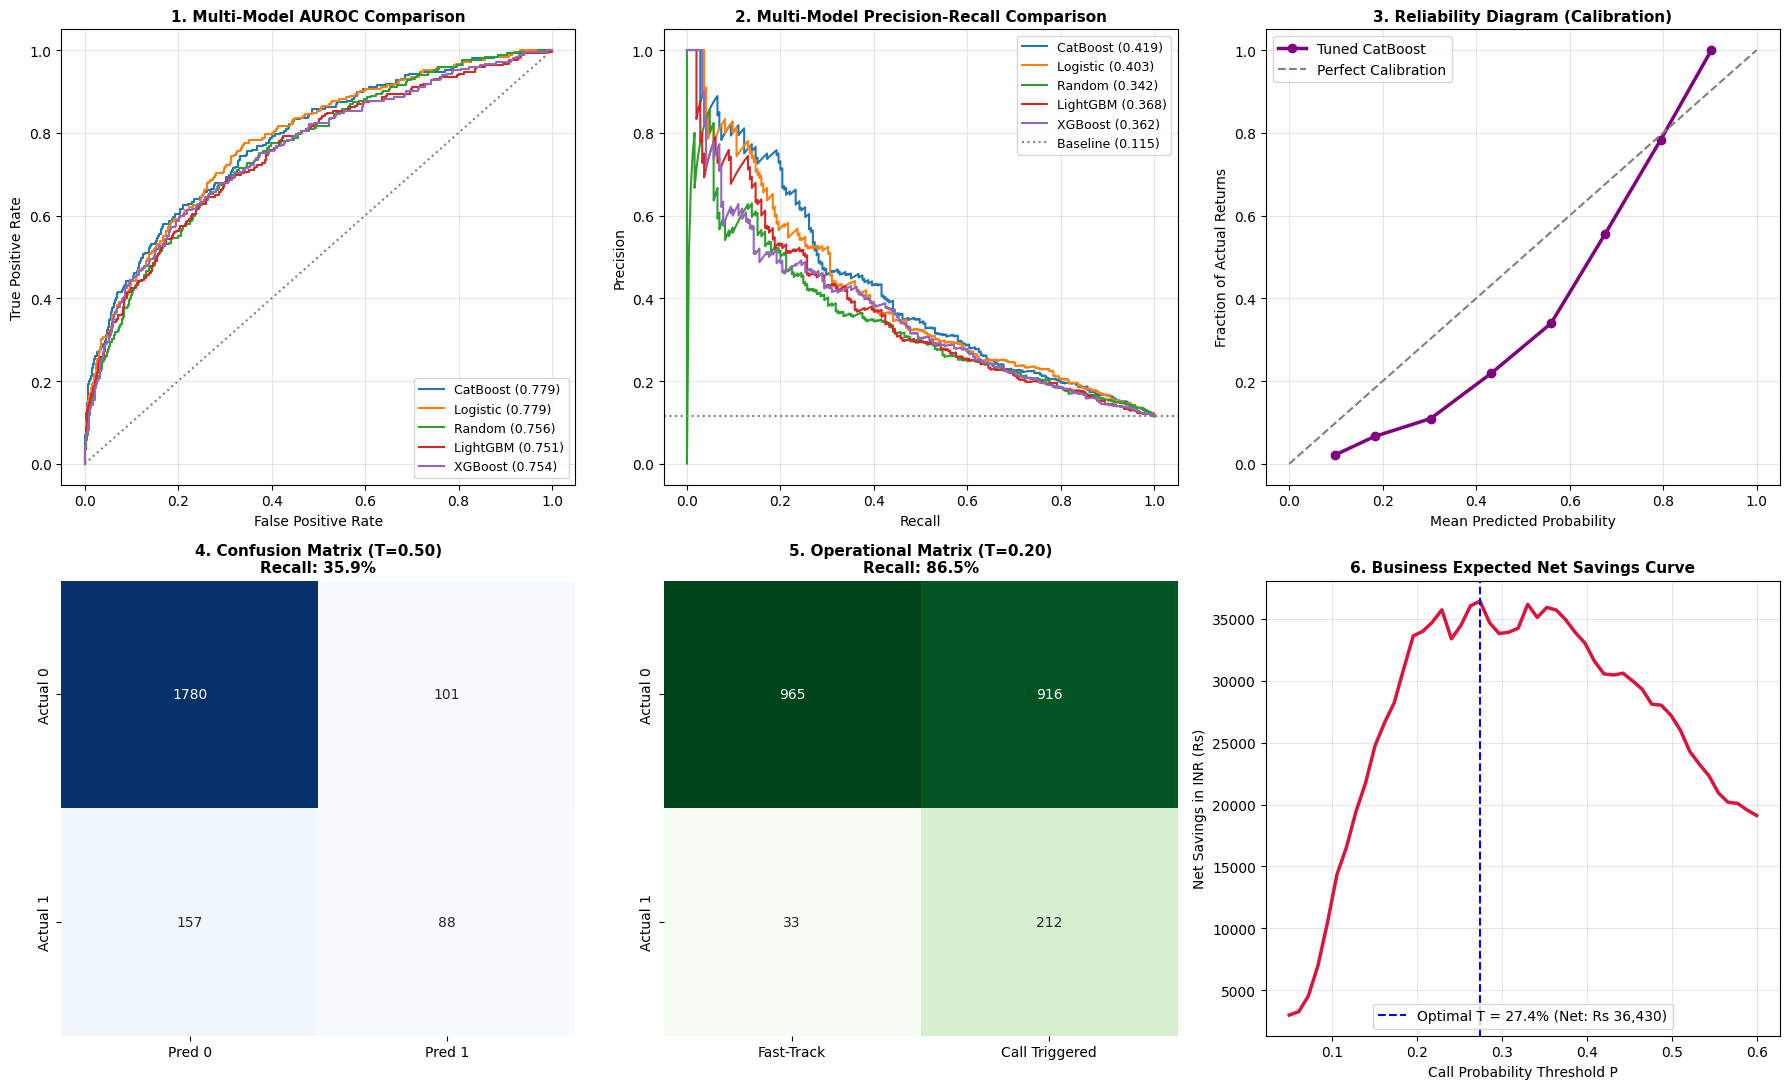

In [8]:
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# 1. Multi-Model ROC
for name, probs in predictions_dict.items():
    fpr, tpr, _ = roc_curve(y_val_oot, probs)
    auc_val = roc_auc_score(y_val_oot, probs)
    axes[0, 0].plot(fpr, tpr, label=f"{name.split(' ')[0]} ({auc_val:.3f})")
axes[0, 0].plot([0, 1], [0, 1], color='gray', linestyle=':')
axes[0, 0].set_title('1. Multi-Model AUROC Comparison', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('False Positive Rate')
axes[0, 0].set_ylabel('True Positive Rate')
axes[0, 0].legend(loc='lower right', fontsize=9)
axes[0, 0].grid(True, alpha=0.3)

# 2. Multi-Model PR Curves
for name, probs in predictions_dict.items():
    p, r, _ = precision_recall_curve(y_val_oot, probs)
    ap_val = average_precision_score(y_val_oot, probs)
    axes[0, 1].plot(r, p, label=f"{name.split(' ')[0]} ({ap_val:.3f})")
axes[0, 1].axhline(y=y_val_oot.mean(), color='gray', linestyle=':', label=f"Baseline ({y_val_oot.mean():.3f})")
axes[0, 1].set_title('2. Multi-Model Precision-Recall Comparison', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('Recall')
axes[0, 1].set_ylabel('Precision')
axes[0, 1].legend(loc='upper right', fontsize=9)
axes[0, 1].grid(True, alpha=0.3)

# 3. Calibration Curve
best_val_probs = best_model.predict_proba(X_val_oot)[:, 1]
prob_true, prob_pred = calibration_curve(y_val_oot, best_val_probs, n_bins=8)
axes[0, 2].plot(prob_pred, prob_true, marker='o', linewidth=2.5, color='purple', label='Tuned CatBoost')
axes[0, 2].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
axes[0, 2].set_title('3. Reliability Diagram (Calibration)', fontsize=11, fontweight='bold')
axes[0, 2].set_xlabel('Mean Predicted Probability')
axes[0, 2].set_ylabel('Fraction of Actual Returns')
axes[0, 2].legend(loc='upper left')
axes[0, 2].grid(True, alpha=0.3)

# 4. Confusion Matrix at 0.50
cm_50 = confusion_matrix(y_val_oot, (best_val_probs >= 0.50).astype(int))
sns.heatmap(cm_50, annot=True, fmt='d', cmap='Blues', ax=axes[1, 0], cbar=False,
            xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
axes[1, 0].set_title(f"4. Confusion Matrix (T=0.50)\nRecall: {recall_score(y_val_oot, (best_val_probs >= 0.50).astype(int)):.1%}", fontsize=11, fontweight='bold')

# 5. Operational Matrix at 0.20
cm_20 = confusion_matrix(y_val_oot, (best_val_probs >= 0.20).astype(int))
sns.heatmap(cm_20, annot=True, fmt='d', cmap='Greens', ax=axes[1, 1], cbar=False,
            xticklabels=['Fast-Track', 'Call Triggered'], yticklabels=['Actual 0', 'Actual 1'])
axes[1, 1].set_title(f"5. Operational Matrix (T=0.20)\nRecall: {recall_score(y_val_oot, (best_val_probs >= 0.20).astype(int)):.1%}", fontsize=11, fontweight='bold')

# 6. Expected Profit Curve
th_range = np.linspace(0.05, 0.60, 50)
savings = []
for th in th_range:
    mask = best_val_probs >= th
    called = mask.sum()
    rets = y_val_oot[mask].sum()
    net = (rets * 0.35 * 1150) - (called * 45)
    savings.append(net)

axes[1, 2].plot(th_range, savings, color='crimson', linewidth=2.5)
opt_idx = np.argmax(savings)
opt_th = th_range[opt_idx]
max_sav = savings[opt_idx]
axes[1, 2].axvline(x=opt_th, color='blue', linestyle='--', label=f"Optimal T = {opt_th:.1%} (Net: Rs {max_sav:,.0f})")
axes[1, 2].set_title('6. Business Expected Net Savings Curve', fontsize=11, fontweight='bold')
axes[1, 2].set_xlabel('Call Probability Threshold P')
axes[1, 2].set_ylabel('Net Savings in INR (Rs)')
axes[1, 2].legend(loc='lower center')
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



## Step 9: Top 20 Feature Importances (Global Explainability)
We extract the exact percentage importance of features driving return risk across historical orders.



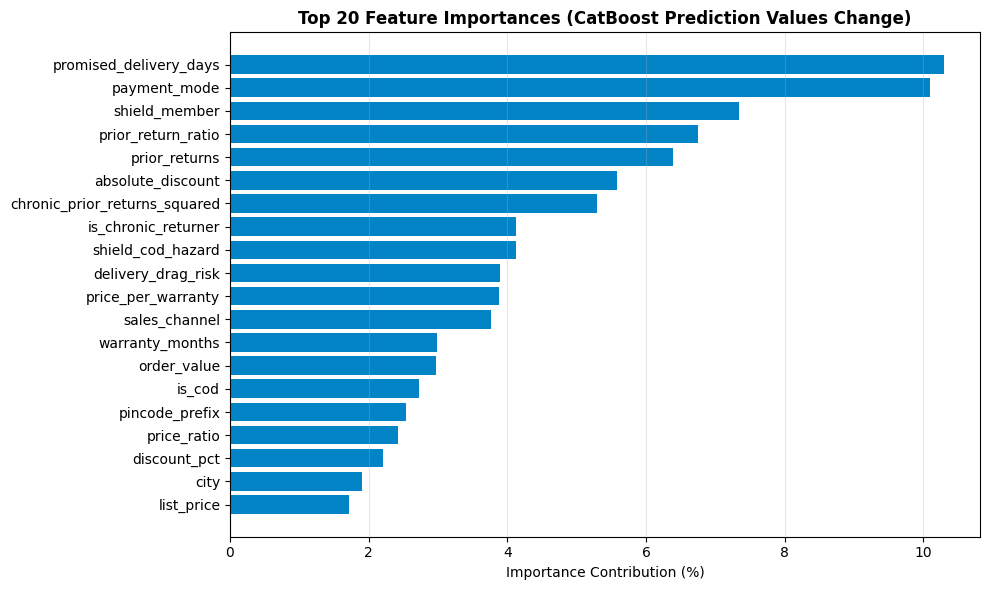

Top 10 Drivers:
                      feature  importance
       promised_delivery_days   10.303323
                 payment_mode   10.095881
                shield_member    7.339447
           prior_return_ratio    6.756711
                prior_returns    6.394859
            absolute_discount    5.588711
chronic_prior_returns_squared    5.288005
          is_chronic_returner    4.128034
            shield_cod_hazard    4.121083
           delivery_drag_risk    3.900910


In [9]:
feat_imp = pd.DataFrame({
    'feature': X_train_oot.columns,
    'importance': best_model.get_feature_importance(Pool(X_val_oot, y_val_oot, cat_features=cat_indices), type='PredictionValuesChange')
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
top20 = feat_imp.head(20).iloc[::-1]
plt.barh(top20['feature'], top20['importance'], color='#0284c7')
plt.title('Top 20 Feature Importances (CatBoost Prediction Values Change)', fontsize=12, fontweight='bold')
plt.xlabel('Importance Contribution (%)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("Top 10 Drivers:")
print(feat_imp.head(10).to_string(index=False))



## Step 10: Error Analysis & Train-vs-Test Drift Audit
1. **Error Profiling:** False Positives (called but kept) vs. False Negatives (missed returns)
2. **Data Drift:** Kolmogorov-Smirnov distribution stability tests between Train and Unlabelled Test data



In [11]:
# ==============================================================================
# Step 10: Error Analysis & Train-vs-Test Drift Audit
# ==============================================================================
from scipy.stats import ks_2samp

# 1. Prepare Audit DataFrame with Product and Customer Metadata
val_df_audit = val_split.copy()

# Merge products to resolve the 'family' column safely
if 'family' not in val_df_audit.columns:
    val_df_audit = val_df_audit.merge(products[['sku', 'family']], on='sku', how='left')

# Ensure probabilities are present
if 'best_val_probs' not in locals():
    best_val_probs = best_model.predict_proba(X_val_oot)[:, 1]

val_df_audit['score'] = best_val_probs
val_df_audit['call_flag'] = (best_val_probs >= 0.20).astype(int)

# 2. Partition into False Positives and False Negatives
fp = val_df_audit[(val_df_audit['call_flag'] == 1) & (val_df_audit['returned'] == 0)]
fn = val_df_audit[(val_df_audit['call_flag'] == 0) & (val_df_audit['returned'] == 1)]
tp = val_df_audit[(val_df_audit['call_flag'] == 1) & (val_df_audit['returned'] == 1)]
tn = val_df_audit[(val_df_audit['call_flag'] == 0) & (val_df_audit['returned'] == 0)]

print("=== ERROR ANALYSIS AUDIT (T=0.20) ===")
print(f"Total Validation Orders:          {len(val_df_audit):,}")
print(f"True Positives (Caught Returns):  {len(tp):,} (Recall: {len(tp)/(len(tp)+len(fn)):.1%})")
print(f"False Positives (Called but Kept):{len(fp):,} orders")
print(f"  • Mean Discount:                {fp['discount_pct'].mean():.1f}%")
print(f"  • COD Payment Share:            {(fp['payment_mode'] == 'cod').mean():.1%}")
print(f"  • Top Categories:               {fp['family'].value_counts().head(3).to_dict()}")

print(f"\nFalse Negatives (Missed Returns): {len(fn):,} orders")
print(f"  • Mean Prior Returns:           {fn['customer_prior_returns'].mean():.2f}")
print(f"  • COD Payment Share:            {(fn['payment_mode'] == 'cod').mean():.1%}")
print(f"  • Top Categories:               {fn['family'].value_counts().head(3).to_dict()}")

# 3. Two-Sample Kolmogorov-Smirnov Data Drift Audit
print("\n=== TRAIN VS TEST DATA DRIFT AUDIT ===")
X_test_oot = preprocessor.transform(test_raw)

drift_features = [
    c for c in ['order_value', 'discount_pct', 'promised_delivery_days', 'tenure_days']
    if c in X_train_oot.columns and c in X_test_oot.columns
]

for col in drift_features:
    ks_stat, p_val = ks_2samp(X_train_oot[col], X_test_oot[col])
    status_str = "Stable" if p_val > 0.01 else "Shifted (Natural Ageing)"
    print(f"{col:25s} | KS Stat: {ks_stat:.4f} | p-value: {p_val:.4f} ({status_str})")

=== ERROR ANALYSIS AUDIT (T=0.20) ===
Total Validation Orders:          2,126
True Positives (Caught Returns):  212 (Recall: 86.5%)
False Positives (Called but Kept):916 orders
  • Mean Discount:                10.6%
  • COD Payment Share:            46.2%
  • Top Categories:               {'Robot Vacuum': 238, 'Water Purifier': 184, 'Air Fryer': 146}

False Negatives (Missed Returns): 33 orders
  • Mean Prior Returns:           0.00
  • COD Payment Share:            12.1%
  • Top Categories:               {'Room Heater': 8, 'Mixer Grinder': 8, 'Ceiling Fan': 7}

=== TRAIN VS TEST DATA DRIFT AUDIT ===
order_value               | KS Stat: 0.0199 | p-value: 0.5130 (Stable)
discount_pct              | KS Stat: 0.0112 | p-value: 0.9825 (Stable)
promised_delivery_days    | KS Stat: 0.0310 | p-value: 0.0785 (Stable)
tenure_days               | KS Stat: 0.2424 | p-value: 0.0000 (Shifted (Natural Ageing))


## Step 11: Retrain on Full Dataset & Generate `predictions.csv`
We fit the best hyperparameter configuration on all 10,504 historical orders, predict `test_unlabelled.csv` (2,096 rows), apply probability calibration back to population prevalence, and trigger direct file download.



In [12]:
print("Fitting preprocessor on full historical orders...")
full_preprocessor = KestrelPreprocessor(customers_df=customers, products_df=products)
full_preprocessor.fit(train_clean, train_clean['returned'])

X_full = full_preprocessor.transform(train_clean)
y_full = train_clean['returned'].values

final_model = CatBoostClassifier(
    depth=best_params['depth'],
    l2_leaf_reg=best_params['l2'],
    learning_rate=best_params['lr'],
    iterations=best_params['iters'],
    scale_pos_weight=best_params['spw'],
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=42,
    verbose=100
)
final_model.fit(Pool(X_full, y_full, cat_features=cat_indices))

# Transform and score test_unlabelled.csv
X_test_final = full_preprocessor.transform(test_raw)
raw_test_scores = final_model.predict_proba(X_test_final)[:, 1]

# Probability calibration: unweight odds back to true population prevalence (~11.4%)
w = best_params.get('spw', 1.0)
if w != 1.0:
    odds = raw_test_scores / np.maximum(1.0 - raw_test_scores, 1e-7)
    cal_odds = odds / w
    test_scores = cal_odds / (1.0 + cal_odds)
else:
    test_scores = raw_test_scores

predictions_df = pd.DataFrame({
    'order_id': test_raw['order_id'],
    'score': np.round(test_scores, 4)
})

predictions_df.to_csv('predictions.csv', index=False)
print(f"\nSaved {len(predictions_df)} predictions to predictions.csv")
print("\nCalibrated Score Distribution Summary:")
print(predictions_df['score'].describe())

if IN_COLAB:
    from google.colab import files
    print("\nDownloading predictions.csv to local machine...")
    files.download('predictions.csv')

predictions_df.head(10)



Fitting preprocessor on full historical orders...
0:	total: 60.4ms	remaining: 30.1s
100:	total: 3.02s	remaining: 12s
200:	total: 5.3s	remaining: 7.89s
300:	total: 7.7s	remaining: 5.09s
400:	total: 10.1s	remaining: 2.5s
499:	total: 13.2s	remaining: 0us

Saved 2096 predictions to predictions.csv

Calibrated Score Distribution Summary:
count    2096.000000
mean        0.101797
std         0.117161
min         0.006300
25%         0.033275
50%         0.060050
75%         0.118500
max         0.892000
Name: score, dtype: float64



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,order_id,score
0,KO2610504,0.1466
1,KO2610505,0.0811
2,KO2610506,0.0911
3,KO2610507,0.0213
4,KO2610508,0.0178
5,KO2610509,0.0360
6,KO2610510,0.0666
7,KO2610511,0.2632
8,KO2610512,0.0340
9,KO2610513,0.2939


## Step 12: Interactive Pre-Dispatch Evaluation Widget
Test any custom order parameters to see real-time return probability, operational recommendation, and plain-English reasons.



In [13]:
def evaluate_order(customer_id, sku, payment_mode, order_val, discount_pct=0, delivery_days=5, prior_orders=0, prior_returns=0, is_shield='N', note=''):
    test_record = {
        'order_id': 'KO-INTERACTIVE-001',
        'order_placed_at': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M'),
        'customer_id': customer_id,
        'sku': sku,
        'sales_channel': 'app',
        'payment_mode': payment_mode,
        'discount_pct': discount_pct,
        'qty': 1,
        'order_value_inr': order_val,
        'promised_delivery_days': delivery_days,
        'delivery_pincode': '440365',
        'is_gift': 'N',
        'customer_prior_orders': prior_orders,
        'customer_prior_returns': prior_returns,
        'delivery_note': note,
        'shield_member': is_shield
    }

    df_single = pd.DataFrame([test_record])
    X_single = full_preprocessor.transform(df_single)
    raw_prob = float(final_model.predict_proba(X_single)[0, 1])

    # Calibrate probability
    w = best_params.get('spw', 1.0)
    cal_odds = (raw_prob / max(1.0 - raw_prob, 1e-7)) / w
    prob = float(cal_odds / (1.0 + cal_odds))

    cost = prob * 1150.0
    net_savings = max((prob * 0.35 * 1150.0) - 45.0, 0.0)

    if prob < 0.11:
        action = "FAST_TRACK_DISPATCH (Ship Normally)"
    elif prob < 0.40:
        action = "TRIGGER_CONFIRMATION_CALL (Rs. 45 Call)"
    elif is_shield == 'Y':
        action = "SHIELD_CONCIERGE_OUTREACH (Call immediately; Do NOT hold)"
    else:
        action = "DESK_MANUAL_REVIEW (Verify address & payment)"

    print(f"=== ORDER EVALUATION RESULT ===")
    print(f"Order ID:                 {test_record['order_id']}")
    print(f"Return Probability:       {prob:.2%}")
    print(f"Operational Action:       {action}")
    print(f"Expected Return Cost:     Rs. {cost:,.2f}")
    print(f"Net Savings from Call:    Rs. {net_savings:,.2f}")

print("--- SCENARIO 1: High Risk COD Robot Vacuum ---")
evaluate_order('KC102992', 'KH-RV-02', 'cod', 16499.0, discount_pct=25, delivery_days=8, prior_orders=3, prior_returns=2, is_shield='N')

print("\n--- SCENARIO 2: Low Risk Prepaid Ceiling Fan ---")
evaluate_order('KC104433', 'KH-CF-02', 'prepaid_upi', 3149.0, discount_pct=10, delivery_days=3, prior_orders=2, prior_returns=0, is_shield='N')



--- SCENARIO 1: High Risk COD Robot Vacuum ---
=== ORDER EVALUATION RESULT ===
Order ID:                 KO-INTERACTIVE-001
Return Probability:       71.49%
Operational Action:       DESK_MANUAL_REVIEW (Verify address & payment)
Expected Return Cost:     Rs. 822.15
Net Savings from Call:    Rs. 242.75

--- SCENARIO 2: Low Risk Prepaid Ceiling Fan ---
=== ORDER EVALUATION RESULT ===
Order ID:                 KO-INTERACTIVE-001
Return Probability:       1.18%
Operational Action:       FAST_TRACK_DISPATCH (Ship Normally)
Expected Return Cost:     Rs. 13.59
Net Savings from Call:    Rs. 0.00


In [15]:
import joblib
from google.colab import files

# Pehle model ko Colab disk par save karein:
joblib.dump(final_model, 'kestrel_catboost_calibrated.joblib')

# Ab download karein:
files.download('kestrel_catboost_calibrated.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>